# Loading the dataset and understanding the data

The bookshop wants clusters of books that share the same topic or theme, derived from the `description` field

In [8]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

# load the bookshop dataset
df = pd.read_csv("CAB330_asm2_datasets 2/Dataset4Task3_26.csv")

# set random_state to be consistent
rs = 42

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Title          5000 non-null   str  
 1   description    5000 non-null   str  
 2   authors        4909 non-null   str  
 3   publisher      4293 non-null   str  
 4   publishedDate  4982 non-null   str  
 5   categories     4744 non-null   str  
dtypes: str(6)
memory usage: 234.5 KB


In [9]:
print(df._get_value(index=0, col='description')[:200])
print(f"Average description length: {df['description'].apply(lambda x: len(x)).mean()}")

Philip Nel takes a fascinating look into the key aspects of Seuss's career - his poetry, politics, art, marketing, and place in the popular imagination." "Nel argues convincingly that Dr. Seuss is one
Average description length: 667.6732


# Preprocessing the description field

In [10]:
import string
import re

from nltk.corpus import stopwords as sw
from nltk.corpus import wordnet as wn
from nltk import WordNetLemmatizer, pos_tag, sent_tokenize, wordpunct_tokenize

lemmatizer = WordNetLemmatizer()
punct = set(string.punctuation)

# no provided stopwords, so just using the default NLTK
stopwords = set(sw.words("english"))

def lemmatize(token, tag):
    tag = {
        'N': wn.NOUN,
        'V': wn.VERB,
        'R': wn.ADV,
        'J': wn.ADJ
    }.get(tag[0], wn.NOUN)
    
    return lemmatizer.lemmatize(token, tag)

def cab_tokenizer(document):
    # init token list
    tokens = []

    # split the document into sentences
    for sent in sent_tokenize(str(document)):
        # split doc into tokens, then create part of speech tag for each
        for token, tag in pos_tag(wordpunct_tokenize(sent)):
            # preprocess and remove unnecessary characters
            token = token.lower()
            token = token.strip()
            token = token.strip('_')
            token = token.strip('*')

            # If stopword, ignore
            if token in stopwords:
                continue

            # If punctuation, ignore
            if all(char in punct for char in token):
                continue
            
            ###########################################################################
            # This is kept for reference of the original method.
            # There are quite a few entries in this dataset with corrupted
            # OCR. For example:
            # Mirror for Magistrates:
            # "H i I 41 1 ffje jWtrror for f EDITED from ORIGINAL TEXTS... I I I I 1"
            # Which is why we want only useful tokens to be extracted.
            ###########################################################################

            # # If number, or other informative token, ignore
            # if any(char.isdigit() for char in token):
            #     continue
            # if len(token) < 2 or not any(char.isalpha() for char in token):
            #     continue

            # keeps useful tokens which aren't standalone characters
            is_word = len(token) >= 2 and token.isalpha()

            # since we have both 'History' and 'Biography & Autobiography',
            # we want to keep useful numbers such as '1960s', '20th', etc,
            # but remove standalone numbers from OCR artifacts or any other
            # useless tokens
            # returns true if:
            # 1. A 4-digit year or decade from 1500 to 2099, with optional 's' (e.g., '1999', '1980s', '2024')
            # 2. A 1- to 2-digit ordinal number (e.g., '1st', '2nd', '3rd', '21st', '19th')
            is_era = bool(re.match(r'^(1[5-9]\d{2}|20\d{2})s?$|^\d{1,2}(st|nd|rd|th)$', token))
            if not (is_word or is_era):
                continue

            # lemmatize the token and add to tokens list
            lemma = lemmatize(token, tag)
            tokens.append(lemma)

    return tokens

print("Preprocessing descriptions...")
books = df

books["processed_description"] = books["description"].apply(cab_tokenizer)
token_counts = books["processed_description"].map(len)
n_empty = int((token_counts == 0).sum())
avg_tokens = float(token_counts.mean())

print(books["processed_description"].head(10))
print()
print(f"Descriptions: {len(books):,}")
print(f"Empty after preprocessing: {n_empty}")
print(f"Average processed length: {avg_tokens:.2f} tokens")
print(token_counts.describe().round(2).to_string())

Preprocessing descriptions...
0    [philip, nel, take, fascinating, look, key, as...
1    [resource, include, twelve, principle, underst...
2    [julia, thomas, find, life, spin, control, dea...
3    [church, christ, biblical, ecclesiology, today...
4    [story, child, st, hyacinth, dominican, plant,...
5    [wardell, recall, experience, foreign, student...
6    [counter, western, view, stereotype, muslim, w...
7    [dramatica, screenwriter, armando, saldana, mo...
8    [acclaimed, teacher, puzzler, evelyn, christen...
9    [herb, caen, popular, columnist, san, francisc...
Name: processed_description, dtype: object

Descriptions: 5,000
Empty after preprocessing: 3
Average processed length: 64.24 tokens
count    5000.00
mean       64.24
std        59.36
min         0.00
25%        20.00
50%        46.00
75%        93.00
max       922.00


Distinct terms: 32,645
Sorted by TF descending: True
TF >= DF for every term: True

Highest-TF terms (head of the TF/DF list):
   term   TF   DF  DF_share
   book 2625 1547    0.3094
    new 1641 1077    0.2154
   life 1577 1016    0.2032
     de 1461  239    0.0478
    one 1289  966    0.1932
   work 1252  785    0.1570
  world 1211  887    0.1774
include 1168  909    0.1818
  story  981  680    0.1360
   make  952  762    0.1524
   time  944  715    0.1430
  first  942  766    0.1532
     en  926  182    0.0364
   year  922  718    0.1436
    use  871  652    0.1304

12 most common terms:
   term   TF   DF  DF_share
   book 2625 1547    0.3094
    new 1641 1077    0.2154
   life 1577 1016    0.2032
     de 1461  239    0.0478
    one 1289  966    0.1932
   work 1252  785    0.1570
  world 1211  887    0.1774
include 1168  909    0.1818
  story  981  680    0.1360
   make  952  762    0.1524
   time  944  715    0.1430
  first  942  766    0.1532
Maximum DF share: 0.3094
Terms with DF

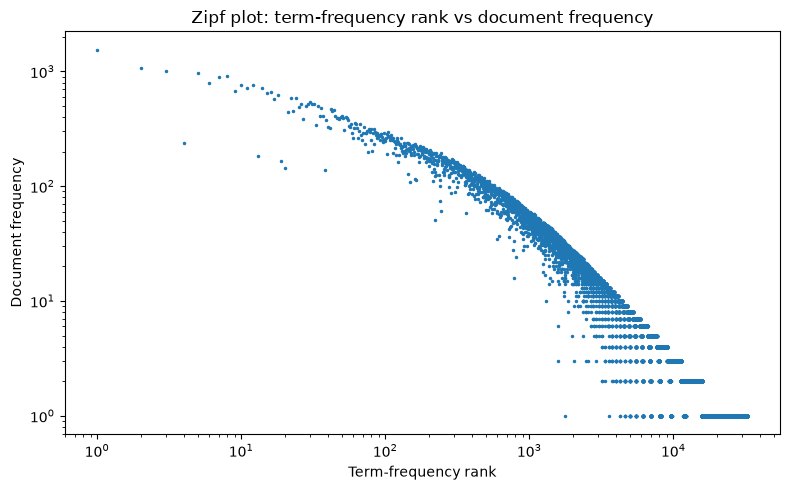

In [11]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

def calculate_tf_df(tokenised_documents):
    """Return (term, TF, DF) rows for a collection of token lists, highest TF first"""
    tf_counts = Counter()
    df_counts = Counter()

    for document in tokenised_documents:
        tf_counts.update(document)
        df_counts.update(set(document))

    rows = [(term, tf_counts[term], df_counts[term]) for term in tf_counts]
    rows.sort(key=lambda row: (-row[1], -row[2], row[0]))
    return rows

def plot_zipf(tf_df_rows):
    """Zipf plot: term-frequency rank (x) against document frequency (y)."""
    ranks = np.arange(1, len(tf_df_rows) + 1)
    document_frequency = np.array([row[2] for row in tf_df_rows])
    fig, ax = plt.subplots(figsize=(8,5))
    ax.loglog(ranks, document_frequency, marker=".", linestyle="none", markersize=3, color="C0")
    ax.set_xlabel("Term-frequency rank")
    ax.set_ylabel("Document frequency")
    ax.set_title("Zipf plot: term-frequency rank vs document frequency")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

tf_df_rows = calculate_tf_df(books["processed_description"])
tf_df_table = pd.DataFrame(tf_df_rows, columns=["term", "TF", "DF"])
tf_df_table["DF_share"] = tf_df_table["DF"] / len(books)

ordered_by_tf = tf_df_table["TF"].is_monotonic_decreasing
tf_at_least_df = bool((tf_df_table["TF"] >= tf_df_table["DF"]).all())

print(f"Distinct terms: {len(tf_df_table):,}")
print(f"Sorted by TF descending: {ordered_by_tf}")
print(f"TF >= DF for every term: {tf_at_least_df}")
print()
print("Highest-TF terms (head of the TF/DF list):")
print(tf_df_table.head(15).to_string(index=False))
print()
print("12 most common terms:")
top12 = tf_df_table.head(12).copy()
print(top12.to_string(index=False))
print(f"Maximum DF share: {tf_df_table['DF_share'].max():.4f}")
print(f"Terms with DF share > 0.7: {int((tf_df_table['DF_share'] > 0.7).sum())}")

plot_zipf(tf_df_rows)

# K-means Model 1, no document-frequency filter

In [12]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

n_clusters = 6 # set in question 3

def visualise_text_cluster(n_clusters, cluster_centers, terms, num_word=5):
    # -- Params --
    # cluster_centers: cluster centers of fitted/trained KMeans/other centroid-based clustering
    # terms: terms used for clustering
    # num_word: number of terms to show per cluster. Change as you please.

    # find features/terms closest to centroids
    ordered_centroids = cluster_centers.argsort()[:, ::-1]

    for cluster in range(n_clusters):
        print("Top terms for cluster {}:".format(cluster), end=" ")
        for term_idx in ordered_centroids[cluster, :num_word]:
            print(terms[term_idx], end=", ")
        print()


def top_terms_table(cluster_centers, terms, num_word=10):
    ordered_centroids = cluster_centers.argsort()[:, ::-1]
    rows = []
    for cluster in range(cluster_centers.shape[0]):
        words = [terms[idx] for idx in ordered_centroids[cluster, :num_word]]
        rows.append({"cluster": cluster, "top_terms": ", ".join(words)})
    return pd.DataFrame(rows)


def cluster_size_table(labels):
    sizes = pd.Series(labels).value_counts().sort_index()
    table = sizes.rename("books").rename_axis("cluster").reset_index()
    table["share"] = (table["books"] / table["books"].sum()).round(3)
    return table


print("Fitting Model 1: TfidfVectorizer(tokenizer=cab_tokenizer) ...")
vectorizer_1 = TfidfVectorizer(tokenizer=cab_tokenizer)
X1 = vectorizer_1.fit_transform(books["description"])
terms_1 = vectorizer_1.get_feature_names_out()
print(f"Model 1 matrix: {X1.shape[0]:,} documents x {X1.shape[1]:,} terms")

kmeans_1 = KMeans(n_clusters=n_clusters, random_state=rs).fit(X1)
labels_1 = kmeans_1.labels_

print()
print("Model 1 cluster sizes:")
print(cluster_size_table(labels_1).to_string(index=False))
print()
visualise_text_cluster(
    kmeans_1.n_clusters, kmeans_1.cluster_centers_, vectorizer_1.get_feature_names_out(), num_word=10
)
print()
print(top_terms_table(kmeans_1.cluster_centers_, terms_1, num_word=10).to_string(index=False))

MODEL1_NAMES = {
    0: "Romance, Family & Domestic Fiction",
    1: "Foreign Language (Dutch Literature)",
    2: "Guides, Children's Books & Practical Non-Fiction",
    3: "History & Political Studies",
    4: "Short Story Anthologies, Biographies & Memoirs",
    5: "Academic Textbooks & Educational Study"
}

books["cluster_1"] = labels_1
print()
print("Model 1 cluster names:")
print(pd.DataFrame(
    {
        "cluster": list(MODEL1_NAMES),
        "name": list(MODEL1_NAMES.values()),
        "books": [int((labels_1 == cluster).sum()) for cluster in MODEL1_NAMES],
    }
).to_string(index=False))
print()
print("Example titles in each Model 1 cluster:")
for cluster in range(n_clusters):
    titles = books.loc[books["cluster_1"] == cluster, "Title"].head(4).tolist()
    print(f"Cluster {cluster} ({MODEL1_NAMES[cluster]}): {titles}")

Fitting Model 1: TfidfVectorizer(tokenizer=cab_tokenizer) ...
Model 1 matrix: 5,000 documents x 32,595 terms

Model 1 cluster sizes:
 cluster  books  share
       0   1009  0.202
       1    157  0.031
       2   1615  0.323
       3    782  0.156
       4    615  0.123
       5    822  0.164

Top terms for cluster 0: find, love, life, one, year, new, woman, time, old, family, 
Top terms for cluster 1: de, en, van, een, het, zijn, op, te, ze, haar, 
Top terms for cluster 2: book, guide, include, child, use, offer, information, color, make, new, 
Top terms for cluster 3: history, war, american, political, century, state, world, first, book, america, 
Top terms for cluster 4: life, story, woman, collection, short, book, world, work, first, write, 
Top terms for cluster 5: book, student, work, edition, text, provide, use, include, new, study, 

 cluster                                                                      top_terms
       0                     find, love, life, one, year, 

# K-means Model 2, document-frequency filter

In [13]:
print("Fitting Model 2: TfidfVectorizer(tokenizer=cab_tokenizer, min_df=3, max_df=0.7) ...")
vectorizer_2 = TfidfVectorizer(tokenizer=cab_tokenizer, min_df=3, max_df=0.7)
X2 = vectorizer_2.fit_transform(books["description"])
terms_2 = vectorizer_2.get_feature_names_out()
print(f"Model 2 matrix: {X2.shape[0]:,} documents x {X2.shape[1]:,} terms")

kmeans_2 = KMeans(n_clusters=n_clusters, random_state=rs).fit(X2)
labels_2 = kmeans_2.labels_
print(f"Terms removed relative to Model 1: {X1.shape[1] - X2.shape[1]:,}")

print()
print("Model 2 cluster sizes:")
print(cluster_size_table(labels_2).to_string(index=False))
print()
visualise_text_cluster(
    kmeans_2.n_clusters, kmeans_2.cluster_centers_, vectorizer_2.get_feature_names_out(), num_word=10
)
print()
print(top_terms_table(kmeans_2.cluster_centers_, terms_2, num_word=10).to_string(index=False))

MODEL2_NAMES = {
    0: "Romance, Family & Domestic Fiction",
    1: "Dutch Literature",
    2: "Guides, Children's Books & Practical Non-Fiction",
    3: "History & Political Studies",
    4: "Literary Anthologies, Poetry & Fiction Collections",
    5: "Academic Textbooks & Educational Reference"
}

books["cluster_2"] = labels_2
print()
print("Model 2 cluster names:")
print(pd.DataFrame(
    {
        "cluster": list(MODEL2_NAMES),
        "name": list(MODEL2_NAMES.values()),
        "books": [int((labels_2 == cluster).sum()) for cluster in MODEL2_NAMES],
    }
).to_string(index=False))
print()
print("Example titles in each Model 2 cluster:")
for cluster in range(n_clusters):
    titles = books.loc[books["cluster_2"] == cluster, "Title"].head(4).tolist()
    print(f"Cluster {cluster} ({MODEL2_NAMES[cluster]}): {titles}")

Fitting Model 2: TfidfVectorizer(tokenizer=cab_tokenizer, min_df=3, max_df=0.7) ...
Model 2 matrix: 5,000 documents x 10,499 terms
Terms removed relative to Model 1: 22,096

Model 2 cluster sizes:
 cluster  books  share
       0   1088  0.218
       1    174  0.035
       2   1540  0.308
       3    895  0.179
       4    523  0.105
       5    780  0.156

Top terms for cluster 0: life, find, love, woman, one, year, world, time, new, family, 
Top terms for cluster 1: de, en, van, een, het, zijn, te, op, ze, haar, 
Top terms for cluster 2: guide, book, include, child, use, color, make, information, offer, provide, 
Top terms for cluster 3: history, war, american, world, political, century, state, book, social, life, 
Top terms for cluster 4: story, collection, work, life, writer, new, volume, poem, one, novel, 
Top terms for cluster 5: book, student, work, use, provide, text, edition, include, new, chapter, 

 cluster                                                                    to

Silhouette uses a fixed random sample of 1000 documents (random_state=42), not the full 5,000-row TF-IDF matrix

Model 1 cosine silhouette: 0.0089  (clusters in sample: [0, 1, 2, 3, 4, 5])
Model 2 cosine silhouette: 0.0135  (clusters in sample: [0, 1, 2, 3, 4, 5])
Model 1 shared top terms (9): ['book', 'first', 'include', 'life', 'new', 'use', 'woman', 'work', 'world']
Model 2 shared top terms (9): ['book', 'include', 'life', 'new', 'one', 'provide', 'use', 'work', 'world']

Model 1 category alignment:
 cluster  books    majority_category  majority_books  majority_share           second_category
       0   1009              Fiction             427           0.423          Juvenile Fiction
       1    157              Fiction              79           0.503                 (missing)
       2   1615             Religion             104           0.064                 (missing)
       3    782              History             208           0.266            Social Science
       4    615  

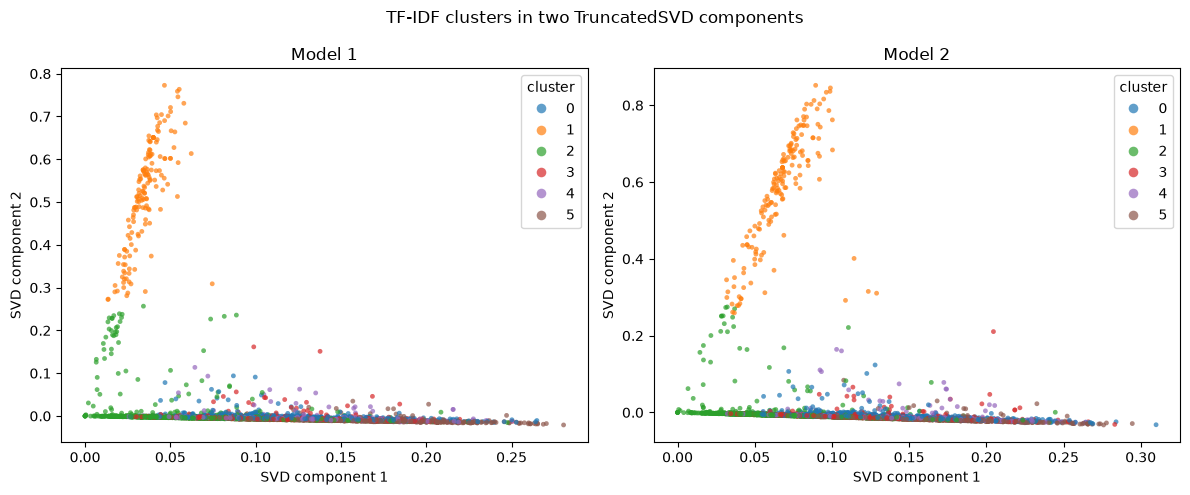

In [14]:
import ast
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

silhouette_sample = 1000

def shared_top_terms(cluster_centers, terms, num_word=10):
    ordered_centroids = cluster_centers.argsort()[:, ::-1]
    counts = Counter()
    for cluster in range(cluster_centers.shape[0]):
        words = [terms[idx] for idx in ordered_centroids[cluster, :num_word]]
        counts.update(set(words))
    shared = sorted(term for term, count in counts.items() if count > 1)
    return shared


def primary_category(value):
    if pd.isna(value):
        return "(missing)"
    parsed = ast.literal_eval(value)
    if isinstance(parsed, list) and parsed:
        return str(parsed[0])
    return str(parsed)


def category_alignment(labels, categories):
    frame = pd.DataFrame({"cluster": labels, "category": categories})
    rows = []
    for cluster, group in frame.groupby("cluster"):
        counts = group["category"].value_counts()
        rows.append(
            {
                "cluster": int(cluster),
                "books": int(len(group)),
                "majority_category": counts.index[0],
                "majority_books": int(counts.iloc[0]),
                "majority_share": round(counts.iloc[0] / len(group), 3),
                "second_category": counts.index[1] if len(counts) > 1 else "",
            }
        )
    table = pd.DataFrame(rows).sort_values("cluster")
    weighted = float(np.average(table["majority_share"], weights=table["books"]))
    return table, weighted


def sampled_silhouette(matrix, labels, sample_index):
    score = silhouette_score(matrix[sample_index], labels[sample_index], metric="cosine")
    present = np.unique(labels[sample_index])
    return float(score), present

sample_index = np.random.RandomState(rs).choice(
    X1.shape[0], size=silhouette_sample, replace=False
)
print(
    f"Silhouette uses a fixed random sample of {silhouette_sample} documents "
    f"(random_state={rs}), not the full {X1.shape[0]:,}-row TF-IDF matrix"
)

sil_1, present_1 = sampled_silhouette(X1, labels_1, sample_index)
sil_2, present_2 = sampled_silhouette(X2, labels_2, sample_index)
shared_1 = shared_top_terms(kmeans_1.cluster_centers_, terms_1, num_word=10)
shared_2 = shared_top_terms(kmeans_2.cluster_centers_, terms_2, num_word=10)
books["primary_category"] = books["categories"].map(primary_category)
align_1, purity_1 = category_alignment(labels_1, books["primary_category"])
align_2, purity_2 = category_alignment(labels_2, books["primary_category"])

print()
print(f"Model 1 cosine silhouette: {sil_1:.4f}  (clusters in sample: {[int(c) for c in present_1]})")
print(f"Model 2 cosine silhouette: {sil_2:.4f}  (clusters in sample: {[int(c) for c in present_2]})")
print(f"Model 1 shared top terms ({len(shared_1)}): {shared_1}")
print(f"Model 2 shared top terms ({len(shared_2)}): {shared_2}")
print()
print("Model 1 category alignment:")
print(align_1.to_string(index=False))
print(f"Weighted majority-category share: {purity_1:.3f}")
print()
print("Model 2 category alignment:")
print(align_2.to_string(index=False))
print(f"Weighted majority-category share: {purity_2:.3f}")

comparison = pd.DataFrame(
    [
        {
            "model": "Model 1 (no DF filter)",
            "terms": int(X1.shape[1]),
            "cosine_silhouette_sample": round(sil_1, 4),
            "shared_top_terms": len(shared_1),
            "weighted_majority_category_share": round(purity_1, 3),
        },
        {
            "model": "Model 2 (min_df=3, max_df=0.7)",
            "terms": int(X2.shape[1]),
            "cosine_silhouette_sample": round(sil_2, 4),
            "shared_top_terms": len(shared_2),
            "weighted_majority_category_share": round(purity_2, 3),
        },
    ]
)
print()
print(comparison.to_string(index=False))

svd_1 = TruncatedSVD(n_components=2, random_state=rs)
xy_1 = svd_1.fit_transform(X1)
svd_2 = TruncatedSVD(n_components=2, random_state=rs)
xy_2 = svd_2.fit_transform(X2)
print()
print(f"Model 1 SVD variance explained by 2 components: {svd_1.explained_variance_ratio_.sum():.3f}")
print(f"Model 2 SVD variance explained by 2 components: {svd_2.explained_variance_ratio_.sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, coords, labels, title in (
    (axes[0], xy_1, labels_1, "Model 1"),
    (axes[1], xy_2, labels_2, "Model 2"),
):
    plot_frame = pd.DataFrame({"x": coords[:, 0], "y": coords[:, 1], "cluster": labels.astype(str)})
    sns.scatterplot(
        data=plot_frame,
        x="x",
        y="y",
        hue="cluster",
        hue_order=[str(cluster) for cluster in range(n_clusters)],
        s=12,
        linewidth=0,
        alpha=0.7,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("SVD component 1")
    ax.set_ylabel("SVD component 2")
    ax.legend(title="cluster", markerscale=2)
fig.suptitle("TF-IDF clusters in two TruncatedSVD components")
fig.tight_layout()
plt.show()
plt.close(fig)